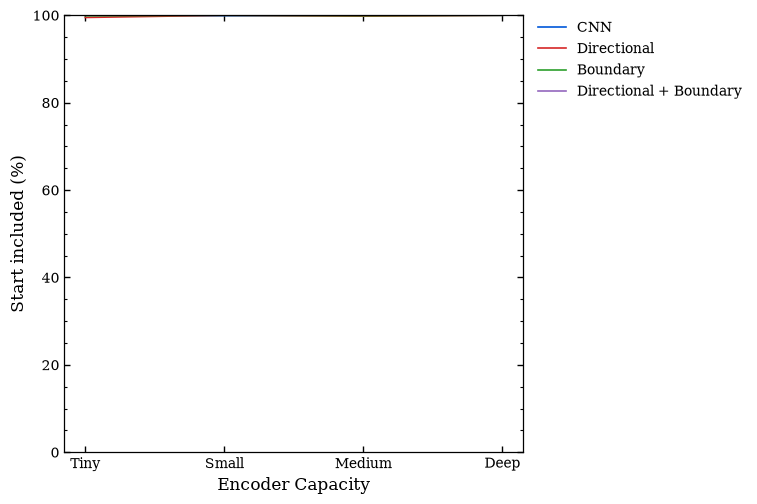

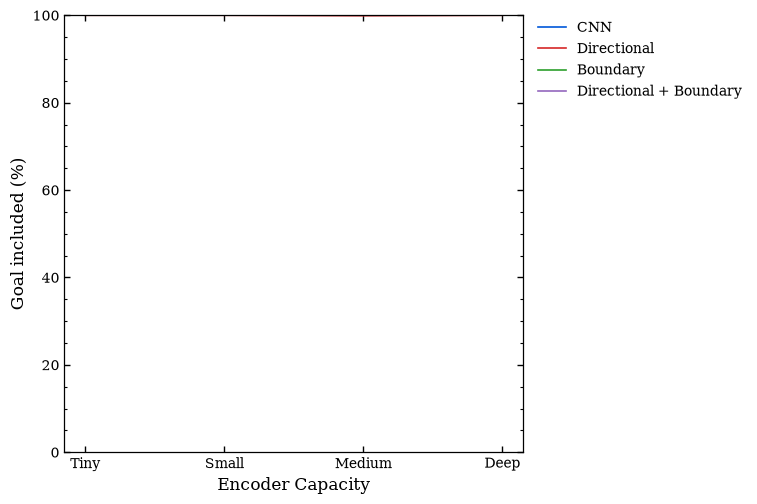

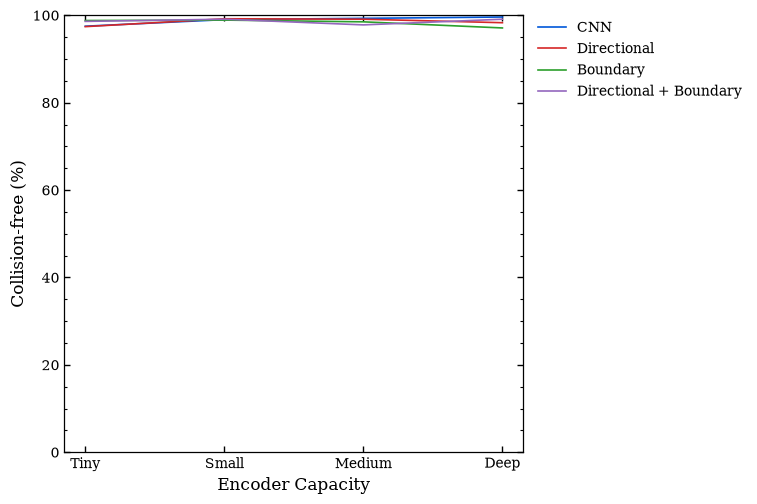

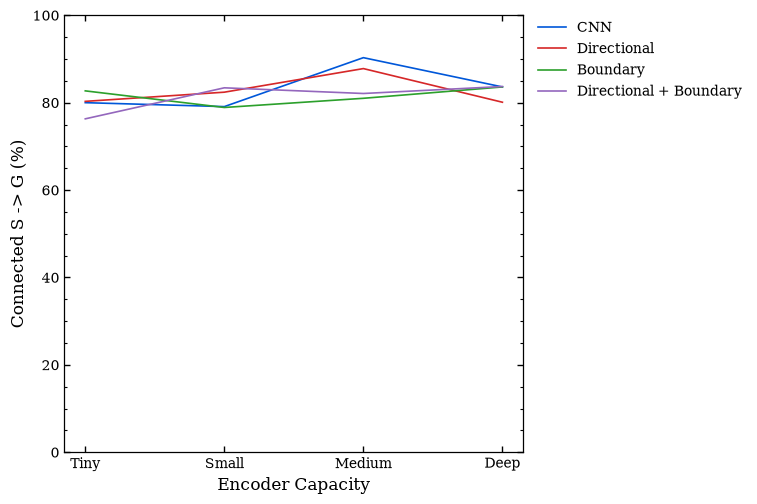

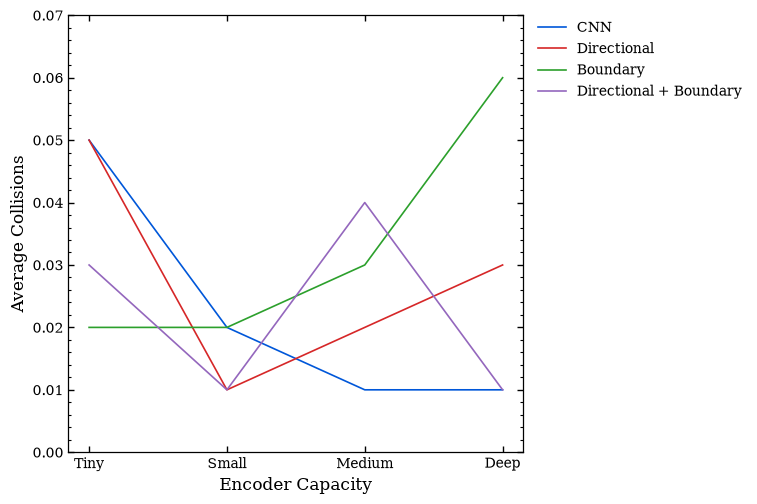

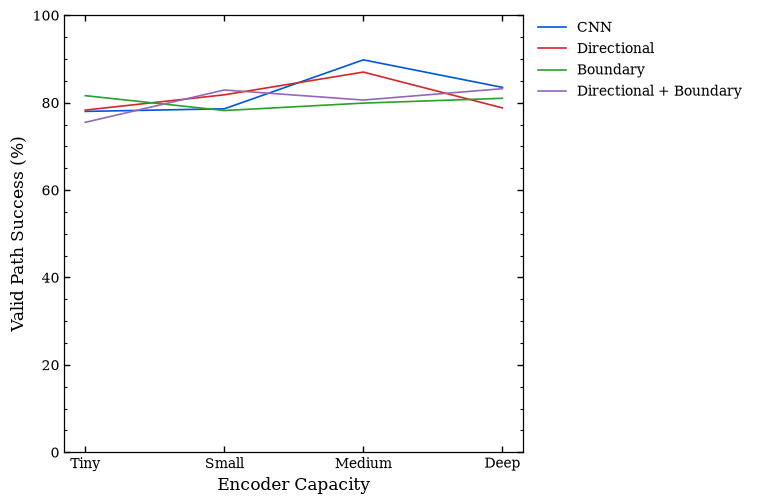

In [5]:
# ============================================================
# Plot one figure per metric
# ============================================================

for metric in metrics:

    # Wider figure
    fig, ax = plt.subplots(figsize=(9.5, 5.2))

    for model_name, model_results in results.items():

        ax.plot(
            x,
            model_results[metric],
            linewidth=1.2,
            # marker="o",          # Use circles for all data points
            markersize=5.5,
            color=styles[model_name]["color"],
            label=model_name,
        )

    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------

    ax.set_xlabel("Encoder Capacity")
    ax.set_xticks(x)
    ax.set_xticklabels(sizes)

    if metric == "Average collisions":
        ax.set_ylabel("Average Collisions")

        # Fixed scale for collision count
        ax.set_ylim(0, 0.07)
        ax.set_yticks(np.arange(0, 0.071, 0.01))

    else:
        ax.set_ylabel(f"{metric} (%)")

        # Same Y-axis scale for all percentage metrics
        ax.set_ylim(0, 100)
        ax.set_yticks(np.arange(0, 101, 20))

    # --------------------------------------------------------
    # Minor ticks
    # --------------------------------------------------------

    ax.yaxis.set_minor_locator(AutoMinorLocator())

    ax.tick_params(
        axis="both",
        which="major",
        length=4,
        width=1.0
    )

    ax.tick_params(
        axis="both",
        which="minor",
        length=2,
        width=0.8
    )

    # --------------------------------------------------------
    # Legend outside, upper right
    # --------------------------------------------------------

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0
    )

    # Reserve space for legend
    plt.tight_layout(rect=[0, 0, 0.82, 1])

    plt.show()

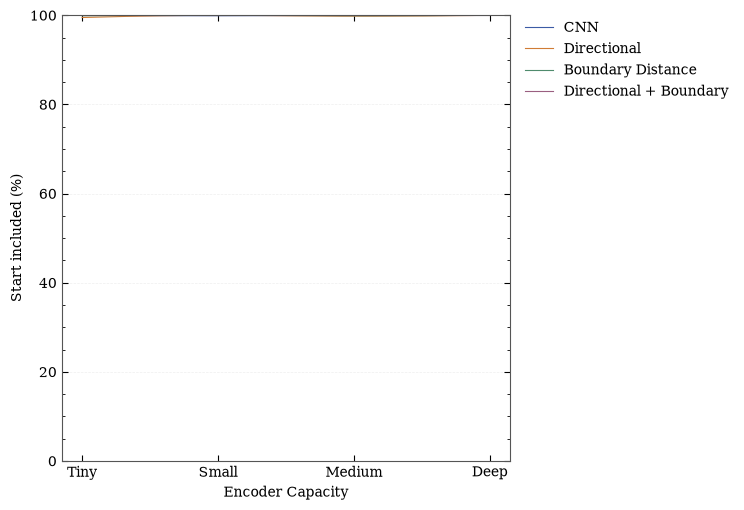

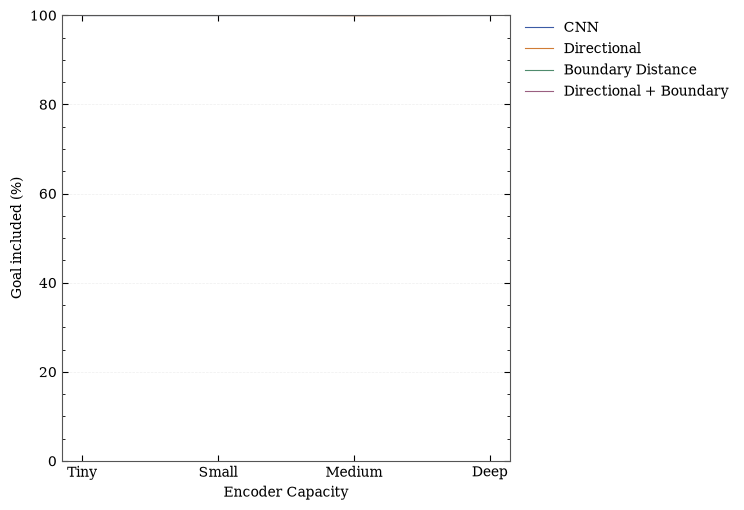

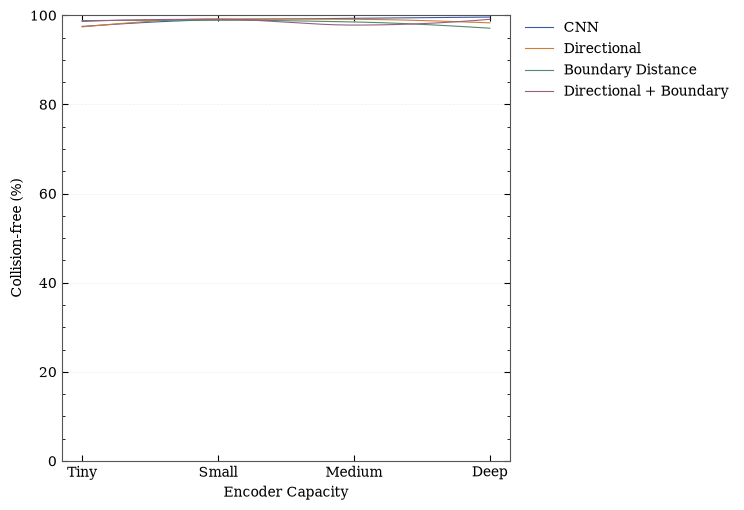

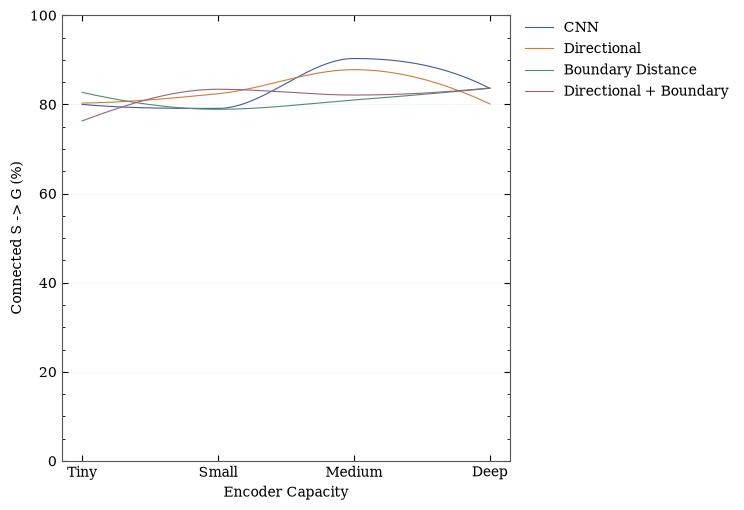

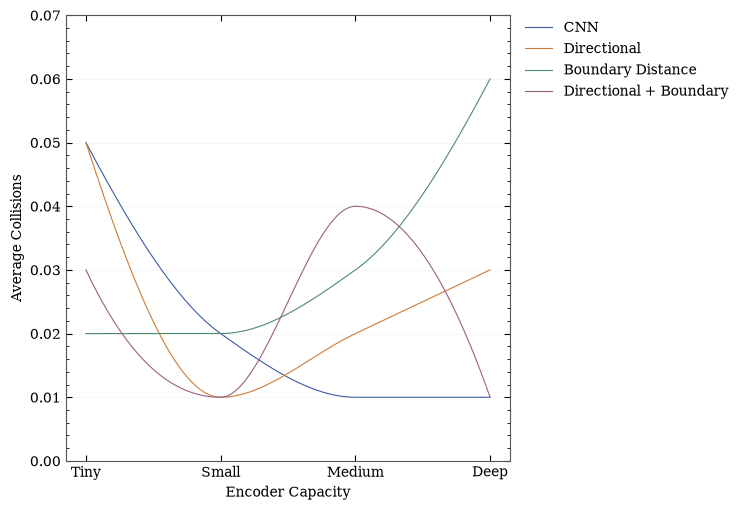

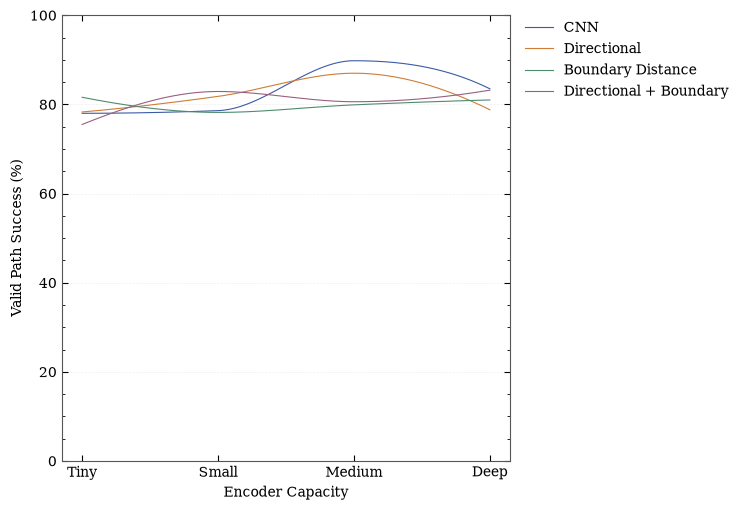

In [22]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.interpolate import PchipInterpolator
from matplotlib.ticker import AutoMinorLocator


# ============================================================
# 1. Experimental results
# ============================================================

sizes = ["Tiny", "Small", "Medium", "Deep"]

results = {

    "CNN": {
        "Start included": [100.0, 99.9, 100.0, 100.0],
        "Goal included": [100.0, 100.0, 100.0, 100.0],
        "Collision-free": [97.5, 99.0, 99.3, 99.6],
        "Connected S -> G": [80.0, 79.1, 90.3, 83.6],
        "Average collisions": [0.05, 0.02, 0.01, 0.01],
        "Valid Path Success": [78.0, 78.6, 89.8, 83.5],
    },

    "Directional": {
        "Start included": [99.5, 100.0, 99.8, 100.0],
        "Goal included": [100.0, 100.0, 99.9, 100.0],
        "Collision-free": [97.4, 99.2, 99.1, 98.3],
        "Connected S -> G": [80.3, 82.4, 87.8, 80.1],
        "Average collisions": [0.05, 0.01, 0.02, 0.03],
        "Valid Path Success": [78.3, 81.8, 87.0, 78.8],
    },

    "Boundary Distance": {
        "Start included": [99.9, 100.0, 99.9, 100.0],
        "Goal included": [100.0, 100.0, 100.0, 100.0],
        "Collision-free": [98.8, 98.9, 98.5, 97.1],
        "Connected S -> G": [82.7, 78.9, 81.0, 83.6],
        "Average collisions": [0.02, 0.02, 0.03, 0.06],
        "Valid Path Success": [81.6, 78.2, 79.9, 81.0],
    },

    "Directional + Boundary": {
        "Start included": [100.0, 100.0, 100.0, 100.0],
        "Goal included": [100.0, 100.0, 100.0, 100.0],
        "Collision-free": [98.6, 99.1, 97.8, 99.1],
        "Connected S -> G": [76.3, 83.4, 82.1, 83.7],
        "Average collisions": [0.03, 0.01, 0.04, 0.01],
        "Valid Path Success": [75.5, 82.9, 80.6, 83.2],
    },
}


# ============================================================
# 2. Metrics to plot
# ============================================================

metrics = [
    "Start included",
    "Goal included",
    "Collision-free",
    "Connected S -> G",
    "Average collisions",
    "Valid Path Success",
]


# ============================================================
# 3. Paper-style colours
# ============================================================

colors = {
    "CNN": "#3B5BA5",                     # muted blue
    "Directional": "#D07C35",             # muted orange
    "Boundary Distance": "#4F8B6D",       # muted green
    "Directional + Boundary": "#9A5F80",  # muted purple
}


# ============================================================
# 4. X-axis
# ============================================================

x = np.arange(len(sizes))

# Dense x coordinates for smooth curves
x_smooth = np.linspace(
    x.min(),
    x.max(),
    300
)


# ============================================================
# 5. Global matplotlib style
# ============================================================

plt.rcParams.update({

    "font.size": 10,

    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,

    "legend.fontsize": 10,

    "axes.linewidth": 0.5,

    "figure.dpi": 100,
})


# ============================================================
# 6. Plot one figure per metric
# ============================================================

for metric in metrics:

    fig, ax = plt.subplots(
        figsize=(9.5, 5.2)
    )

    # --------------------------------------------------------
    # Plot each encoder
    # --------------------------------------------------------

    for model_name, model_results in results.items():

        y = np.asarray(
            model_results[metric],
            dtype=float
        )

        # Shape-preserving smooth interpolation
        interpolator = PchipInterpolator(
            x,
            y
        )

        y_smooth = interpolator(
            x_smooth
        )

        # Smooth curve only
        ax.plot(
            x_smooth,
            y_smooth,
            linewidth=0.8,
            color=colors[model_name],
            label=model_name,
        )


    # ========================================================
    # X-axis
    # ========================================================

    ax.set_xlabel(
        "Encoder Capacity"
    )

    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        sizes
    )


    # ========================================================
    # Y-axis
    # ========================================================

    if metric == "Average collisions":

        ax.set_ylabel(
            "Average Collisions"
        )

        ax.set_ylim(
            0,
            0.07
        )

        ax.set_yticks(
            np.arange(
                0,
                0.071,
                0.01
            )
        )

    else:

        ax.set_ylabel(
            f"{metric} (%)"
        )

        ax.set_ylim(
            0,
            100
        )

        ax.set_yticks(
            np.arange(
                0,
                101,
                20
            )
        )


    # ========================================================
    # Minor ticks
    # ========================================================

    ax.yaxis.set_minor_locator(
        AutoMinorLocator()
    )

    ax.tick_params(
        axis="both",
        which="major",
        length=4,
        width=0.8
    )

    ax.tick_params(
        axis="both",
        which="minor",
        length=2,
        width=0.6
    )


    # ========================================================
    # Paper-style frame
    # ========================================================

    # Full rectangular border
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#555555")
        
    # Lighten left and bottom borders
    ax.spines["left"].set_color("#555555")
    ax.spines["bottom"].set_color("#555555")

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)


    # ========================================================
    # Light horizontal grid
    # ========================================================

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.5,
        alpha=0.20
    )

    # Keep curves above grid
    ax.set_axisbelow(True)


    # ========================================================
    # Legend
    # ========================================================

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0,
        frameon=False,
    )


    # ========================================================
    # Layout
    # ========================================================

    plt.tight_layout(
        rect=[0, 0, 0.80, 1]
    )

    plt.show()